In [1]:
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import auc, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    augment_patient_and_cat_specific,
    find_all_indices,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

__IIVV-results from statistical evaluation__

## Contents

- SNR Data augmentation tuning
- Model tuning
    - SVM tuning
    - RF tuning
    - LR tuning



**Data loading**

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_lr_hr,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_lr_hr"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_lr_hr"
# class_task = "MC"

data_augmentation = False

\Cancer vs. Low risk vs. High risk

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


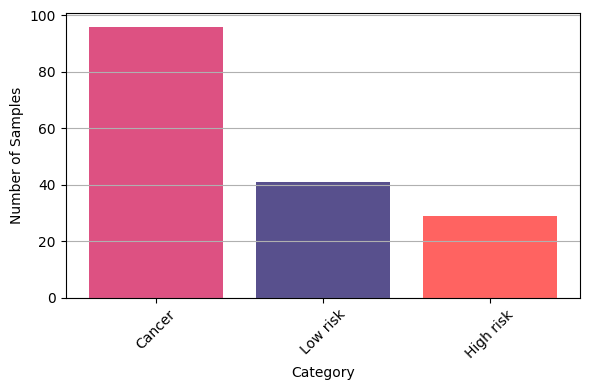


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)


In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    # for SVD kernel boundary
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#003F5C",  # healthy
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # healthy
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "cancer_vs_lr_hr":
    print("\Cancer vs. Low risk vs. High risk\n")
    select_idx = find_all_indices(
        labels_cancer_vs_lr_hr, ["Cancer", "High risk", "Low risk"], split=False
    )
    labels = labels_cancer_vs_lr_hr[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#FFA600",  # cancer
        1: "#FF6361",  # "High risk
        2: "#58508D",  # "Low risk
    }
    cp_l = {
        0: "cancer",  # cancer
        1: "High risk",  # High risk
        2: "Low risk",  # Low risk
    }
    visualize_Category_hist(labels)

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "High-grade dysplasia", "Non-malignant"],
        split=False,
    )
    labels = labels_MC[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        3: "#58508D",  # Non-malignant
        0: "#FFA600",  # Cancer
        1: "#003F5C",  # Healthy
        2: "#FF6361",  # High-grade dysplasia
    }
    cp_l = {
        0: "Cancer",
        1: "Healthy",
        2: "High-grade dysplasia",
        3: "Non-malignant",
    }
    aug_dict = {
        "High-grade dysplasia": 70,
        "Non-malignant": 70,
    }

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

if class_task == "MC" and data_augmentation:
    print("\n\t\tBefore augmentation")
    visualize_Category_hist(labels)
    X, Y_labels, labels, Case = augment_patient_and_cat_specific(
        X, Y_labels, labels, Case, aug_dict
    )
    print("\n\t\tAfter augmentation")
    visualize_Category_hist(labels)

# Model tuning

**Tuning using `GridSearch()` with `GroupKFold()` train/test data split**

- SVM tuning
- RF tuning
- LR tuning

In [6]:
n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]
print(f"{top_freqs_baseline=}")
# Top frequency groups for Task 1: 5,6,8,7, Task 2: 3,4,2,5, Task 3: 23,28,24,27

if class_task == "healthy_vs_cancer":
    print("Task 1: 5,6,8,7")
    Freq_sel = {
        "Top 5": top_freqs_baseline[:5],
        "Top 6": top_freqs_baseline[:6],
        "Top 8": top_freqs_baseline[:8],
        "Top 7": top_freqs_baseline[:7],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "cancer_vs_lr_hr":
    print("Task 2: 4,2,29,17")
    Freq_sel = {
        "Top 4": top_freqs_baseline[:4],
        "Top 2": top_freqs_baseline[:2],
        "Top 29": top_freqs_baseline[:29],
        "Top 17": top_freqs_baseline[:17],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
if class_task == "MC":
    print("Task 3: 23,28,24,27")
    Freq_sel = {
        "Top 23": top_freqs_baseline[:23],
        "Top 28": top_freqs_baseline[:28],
        "Top 24": top_freqs_baseline[:24],
        "Top 31": top_freqs_baseline[:31],
        # "All": top_freqs_baseline,  # np.arange(31),
    }

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}
print(Mask_sel)

top_freqs_baseline=array([30,  7,  0, 12, 29,  8, 13, 26, 28, 16,  9, 27,  1, 11, 17, 15, 10,
       25, 24,  4, 21, 22, 20, 19,  5,  6,  3,  2, 14, 23, 18])
Task 2: 4,2,29,17
{'Skip1 medium': 'skip1_medium', 'Skip1 far': 'skip1_far', 'Opp. medium': 'opposite_medium', 'Opp. far': 'opposite_far'}


## SVM tuning

In [7]:
stats_df = []
use_model = "SVM"

param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):

            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)
            """
            for fold, (train_idx, test_idx) in enumerate(cv.split(X_tmp, Y_labels, groups=Case), 1):
                print(f"Fold {fold}")
                print("  Train groups:", Case[train_idx])
                print("  Test groups :", Case[test_idx])
                print("  Train idx   :", train_idx)
                print("  Test idx    :", test_idx)
                print()
            """
            m = SVC(probability=True, random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )

            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv", index=False)

In [8]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv")

In [9]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

   hpt_combinations   val AUC
0      linear_0.001  0.783654
1       linear_0.01  0.788882
2        linear_0.1  0.794169
3        linear_1.0  0.785951
4        poly_0.001  0.761585
5         poly_0.01  0.761344
6          poly_0.1  0.797685
7          poly_1.0  0.778813
8         poly_10.0  0.761817
9        poly_100.0  0.783744
10        rbf_0.001  0.775129
11          rbf_0.1  0.779661
12          rbf_1.0  0.772240
13         rbf_10.0  0.784496
14        rbf_100.0  0.790134
15       rbf_1000.0  0.767478
16    sigmoid_0.001  0.785941
17     sigmoid_0.01  0.785264
18      sigmoid_0.1  0.787805
19      sigmoid_1.0  0.802839

Column: hpt_combinations
hpt_combinations
linear_0.001     30
sigmoid_0.001    22
linear_0.1       20
linear_0.01      19
poly_100.0       13
rbf_1.0          11
linear_1.0        7
rbf_10.0          7
sigmoid_0.1       7
poly_0.1          5
sigmoid_0.01      4
rbf_0.1           4
poly_1.0          3
rbf_1000.0        2
rbf_100.0         1
poly_10.0         1
poly_0.

[Plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

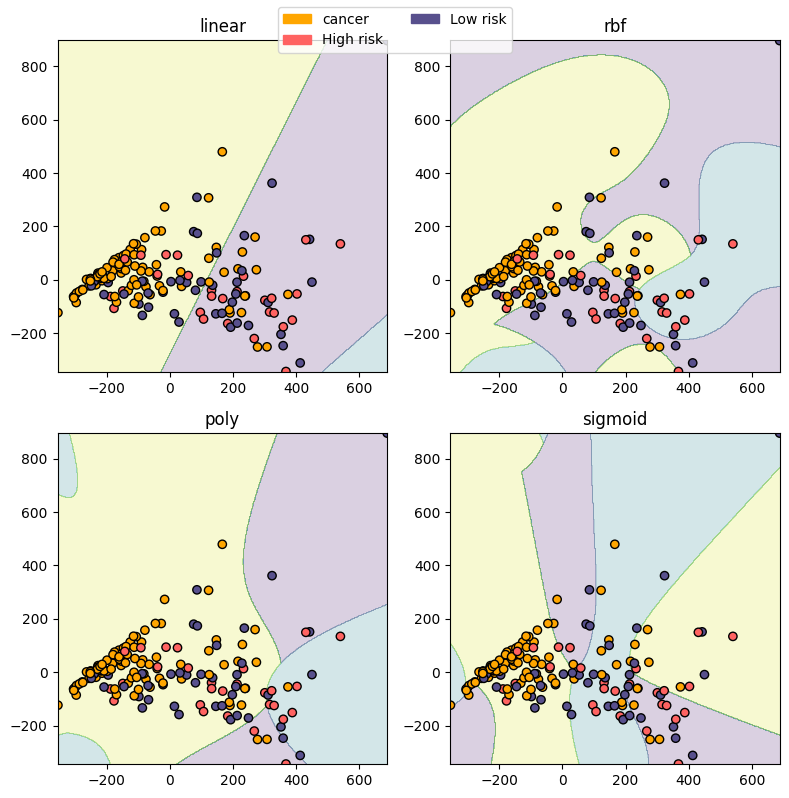

In [10]:
C_val = 10

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

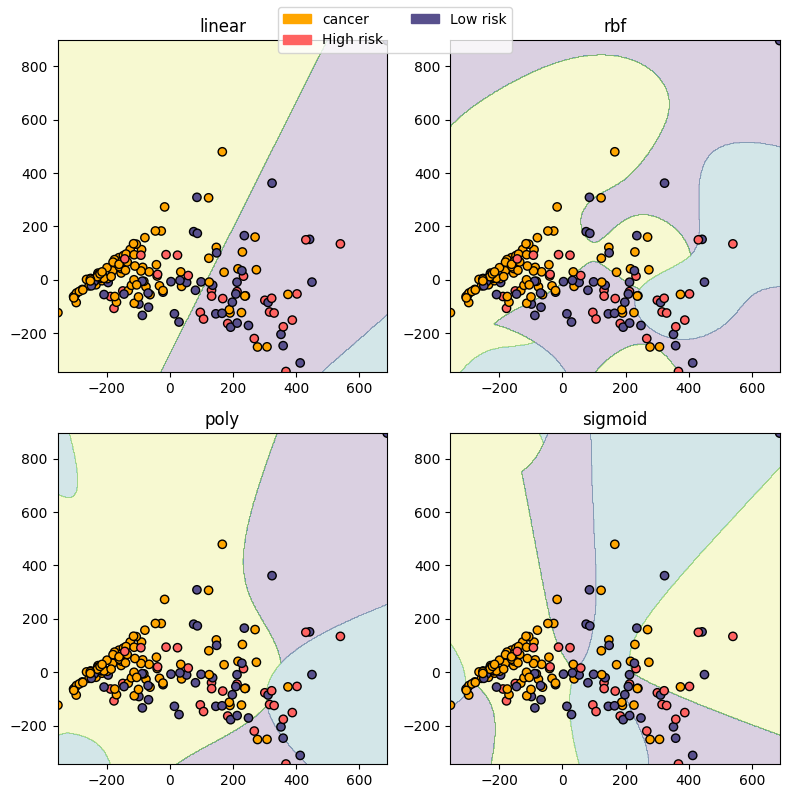

In [11]:
C_val = 1000

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

## RF tuning

In [ ]:
stats_df = []
use_model = "RF"

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = RandomForestClassifier(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)
df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_RF_{class_task}.csv", index=False)

In [ ]:
param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_RF_{class_task}.csv")

In [ ]:
df

In [ ]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

In [ ]:
df

### LR tuning

In [ ]:
stats_df = []
use_model = "LR"

param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10],
    "max_iter": [100, 1000],
    # "solver": ["saga"],
}

for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = LogisticRegression(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_LR_{class_task}.csv", index=False)

In [ ]:
param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10],
    "max_iter": [100, 1000],
    # "solver": ["saga"],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_LR_{class_task}.csv")

In [ ]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

___